In [1]:
import pandas as pd
print(pd.__version__)

2.3.3


In [2]:
sales  = pd.read_csv("RawData/fact_sales.csv")
dealer = pd.read_csv("RawData/dim_dealer.csv")
war    = pd.read_csv("RawData/fact_warranty.csv")

print("Loaded:", len(sales), len(dealer), len(war))
sales.head()

Loaded: 62980 120 8530


,OrderID,OrderDate,DealerID,ProductID,Quantity,UnitPrice,UnitCost,DiscountPct,PaymentTerms,PromisedDays,DeliveryDays,PlantID,BatchID,Revenue,COGS,GrossProfit,IsOnTime
0,ORD-022305,2023-07-15,D082,P005,1,12510,6958,0.08,Advance,3,4,PL1,SHM-2305,11509.2,6958,4551.2,0
1,ORD-027258,2023-11-09,D077,P004,67,9550,5214,0.33,Net 60,7,5,PL5,BLR-2310,428699.5,349338,79361.5,1
2,ORD-042284,2024-10-18,D031,P011,1,2330,1316,0.10,Advance,3,1,PL3,HSR-2407,2097.0,1316,781.0,1
3,ORD-055260,2025-07-23,D061,P024,3,59280,37538,0.13,Net 45,7,7,PL4,HLD-2506,154720.8,112614,42106.8,1
4,ORD-015663,2023-02-04,D086,P012,2,1510,843,0.11,Net 15,3,1,PL3,HSR-2211,2687.8,1686,1001.8,1


In [3]:
print("Rows, Columns:", sales.shape)
print("Dates in DD-MM-YYYY format:", (~sales["OrderDate"].str.match(r"^\d{4}-\d{2}-\d{2}$")).sum())
print("Negative quantity:", (sales["Quantity"] < 0).sum())
print("Zero quantity:", (sales["Quantity"] == 0).sum())
print("Blank DiscountPct:", sales["DiscountPct"].isna().sum())
print("Blank DeliveryDays:", sales["DeliveryDays"].isna().sum())
print("Duplicate rows:", sales.duplicated().sum())

Rows, Columns: (62980, 17)
Dates in DD-MM-YYYY format: 0
Negative quantity: 0
Zero quantity: 0
Blank DiscountPct: 0
Blank DeliveryDays: 0
Duplicate rows: 0


## Romove duplicates rows


In [4]:
before = len(sales)
sales = sales.drop_duplicates()
print("Removed:", before - len(sales), "| Rows now:", len(sales))

Removed: 0 | Rows now: 62980


# repair date format 

In [5]:
d1 = pd.to_datetime(sales["OrderDate"], format="%Y-%m-%d", errors="coerce")
d2 = pd.to_datetime(sales["OrderDate"], format="%d-%m-%Y", errors="coerce")
sales["OrderDate"] = d1.fillna(d2)

print("Failed dates:", sales["OrderDate"].isna().sum())
print(sales["OrderDate"].min(), "to", sales["OrderDate"].max())

Failed dates: 0
2022-01-01 00:00:00 to 2025-12-31 00:00:00


# Quantity Issue

In [6]:
zero = (sales["Quantity"] == 0).sum()
sales = sales[sales["Quantity"] != 0]

neg = (sales["Quantity"] < 0).sum()
sales["Quantity"] = sales["Quantity"].abs()

print("Zero dropped:", zero, "| Negative fixed:", neg, "| Rows now:", len(sales))

Zero dropped: 0 | Negative fixed: 0 | Rows now: 62980


# Blank discount PCT

In [7]:
sales = sales.merge(dealer[["DealerID", "DealerType"]], on="DealerID", how="left")

blank = sales["DiscountPct"].isna().sum()
sales["DiscountPct"] = sales["DiscountPct"].fillna(
    sales.groupby("DealerType")["DiscountPct"].transform("median"))
print("Filled:", blank, "| Blank now:", sales["DiscountPct"].isna().sum())

Filled: 0 | Blank now: 0


## Blank Delivery days

In [8]:
print("Blank delivery days:", sales["DeliveryDays"].isna().sum())
sales["DeliveryDays"] = sales["DeliveryDays"].fillna(sales["PromisedDays"]).astype(int)
print("Blank now:", sales["DeliveryDays"].isna().sum())

Blank delivery days: 0
Blank now: 0


# Create Calculated columns

In [9]:
sales["Revenue"]     = (sales["Quantity"] * sales["UnitPrice"] * (1 - sales["DiscountPct"])).round(2)
sales["COGS"]        = sales["Quantity"] * sales["UnitCost"]
sales["GrossProfit"] = (sales["Revenue"] - sales["COGS"]).round(2)
sales["IsOnTime"]    = (sales["DeliveryDays"] <= sales["PromisedDays"]).astype(int)
sales = sales.drop(columns=["DealerType"])    # Step 9 madhe merge sathi ghetla hota, ata nako

print("Total revenue (Cr):", round(sales["Revenue"].sum() / 1e7, 2))
print("Gross profit %:", round(sales["GrossProfit"].sum() / sales["Revenue"].sum() * 100, 1))
print("On-time %:", round(sales["IsOnTime"].mean() * 100, 1))

Total revenue (Cr): 567.91
Gross profit %: 28.2
On-time %: 80.1


# check sales table final

In [10]:
print(sales.shape, "| nulls:", sales.isna().sum().sum())
print(sales.dtypes)

(62980, 17) | nulls: 0
OrderID                 object
OrderDate       datetime64[ns]
DealerID                object
ProductID               object
Quantity                 int64
UnitPrice                int64
UnitCost                 int64
DiscountPct            float64
PaymentTerms            object
PromisedDays             int64
DeliveryDays             int64
PlantID                 object
BatchID                 object
Revenue                float64
COGS                     int64
GrossProfit            float64
IsOnTime                 int64
dtype: object


In [11]:
# clean Dealer Table

In [12]:
print("Region BEFORE:")
print(dealer["Region"].value_counts())

dealer["Region"]     = dealer["Region"].str.strip().str.title()
dealer["DealerName"] = dealer["DealerName"].str.strip()
dealer["State"]      = dealer["State"].replace({"Maharastra": "Maharashtra", "MH": "Maharashtra"})
dealer["City"]       = dealer["City"].fillna("Unknown")

print("\nRegion AFTER:")
print(dealer["Region"].value_counts())
print("States:", dealer["State"].nunique(), "| Blank city:", dealer["City"].isna().sum())

Region BEFORE:
Region
South    38
North    32
West     32
East     18
Name: count, dtype: int64

Region AFTER:
Region
South    38
North    32
West     32
East     18
Name: count, dtype: int64
States: 21 | Blank city: 0


###  Clean Warranty table

In [13]:
print("Raw rows:", len(war))

war = war.drop_duplicates()

c1 = pd.to_datetime(war["ClaimDate"], format="%Y-%m-%d", errors="coerce")
c2 = pd.to_datetime(war["ClaimDate"], format="%d-%m-%Y", errors="coerce")
war["ClaimDate"] = c1.fillna(c2)

print("Reasons BEFORE:", war["Reason"].nunique())
war["Reason"] = war["Reason"].str.strip().str.title().fillna("Unknown")
print("Reasons AFTER:", war["Reason"].nunique())

war = war[war["ClaimDate"] >= "2022-01-01"]        # claim date 2021 chi = chukicha
war = war[war["OrderID"].isin(sales["OrderID"])]   # valid order nasel tar claim nako

print("Clean rows:", len(war))

Raw rows: 8530
Reasons BEFORE: 10
Reasons AFTER: 10
Clean rows: 8530


## Step 15: Save clean files


In [14]:
print("sales:", sales.shape)
print("dealer regions:", dealer["Region"].nunique())
print("warranty rows:", len(war))

sales: (62980, 17)
dealer regions: 4
warranty rows: 8530


In [15]:
RAW_FOLDER   = "RawData"
CLEAN_FOLDER = "Data clean"     # %ls madhe jasa disla tasa exact

sales.to_csv(f"{CLEAN_FOLDER}/fact_sales.csv", index=False)
dealer.to_csv(f"{CLEAN_FOLDER}/dim_dealer.csv", index=False)
war.to_csv(f"{CLEAN_FOLDER}/fact_warranty.csv", index=False)


# prod.to_csv(f"{CLEAN_FOLDER}/dim_product.csv", index=False)

print("Saved 4 files:", len(sales), len(dealer), len(war), len(prod))

NameError: name 'prod' is not defined

In [ ]:
%ls

# EDA

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [17]:
CLEAN_FOLDER = "Data clean"        # tuzya clean folder cha exact nav lihi
Path("images").mkdir(exist_ok=True)   # charts ithe save hotil

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)

sales  = pd.read_csv(f"{CLEAN_FOLDER}/fact_sales.csv", parse_dates=["OrderDate"])
dealer = pd.read_csv(f"{CLEAN_FOLDER}/dim_dealer.csv")
war    = pd.read_csv(f"{CLEAN_FOLDER}/fact_warranty.csv", parse_dates=["ClaimDate"])
prod   = pd.read_csv(f"{CLEAN_FOLDER}/dim_product.csv")

print("sales:", sales.shape, "| dealer:", dealer.shape, "| warranty:", war.shape, "| product:", prod.shape)
print("OrderDate type:", sales["OrderDate"].dtype)

sales: (62980, 17) | dealer: (120, 8) | warranty: (8530, 12) | product: (24, 9)
OrderDate type: datetime64[ns]


In [18]:
sales["Year"]      = sales["OrderDate"].dt.year
sales["Month"]     = sales["OrderDate"].dt.month
sales["YearMonth"] = sales["OrderDate"].dt.to_period("M").astype(str)
sales["DayName"]   = sales["OrderDate"].dt.day_name()

sales[["OrderDate", "Year", "Month", "YearMonth", "DayName"]].head(3)


,OrderDate,Year,Month,YearMonth,DayName
0,2023-07-15,2023,7,2023-07,Saturday
1,2023-11-09,2023,11,2023-11,Thursday
2,2024-10-18,2024,10,2024-10,Friday


# numpy operations

##  numpy: labels and outliers
np.where (don options), np.select (jast options), np.percentile (khup motha orders shodhne).

In [19]:
# np.where: condition khari tar ek value, nahi tar dusri
sales["DeliveryStatus"] = np.where(sales["IsOnTime"] == 1, "On time", "Late")

# np.select: don peksha jast conditions
conditions = [sales["Quantity"] <= 4, sales["Quantity"] <= 40]
sales["OrderSize"] = np.select(conditions, ["Small", "Medium"], default="Bulk")

print(sales["DeliveryStatus"].value_counts())
print(sales["OrderSize"].value_counts())

# np.percentile: outlier shodhne (IQR method)
q1, q3 = np.percentile(sales["Revenue"], [25, 75])
upper = q3 + 1.5 * (q3 - q1)
outliers = (sales["Revenue"] > upper).sum()
print("Q1:", round(q1), "| Q3:", round(q3), "| Upper limit:", round(upper))
print("Outlier orders:", outliers, "| share %:", round(outliers / len(sales) * 100, 1))
print("Outlier revenue share %:", round(sales.loc[sales["Revenue"] > upper, "Revenue"].sum() / sales["Revenue"].sum() * 100, 1))

DeliveryStatus
On time    50418
Late       12562
Name: count, dtype: int64
OrderSize
Small     37137
Medium    21831
Bulk       4012
Name: count, dtype: int64
Q1: 9139 | Q3: 109648 | Upper limit: 260413
Outlier orders: 6600 | share %: 10.5
Outlier revenue share %: 51.2


Tin tables ekatra (merge)

## Step 19: Combine sales + dealer + product
Analysis sathi ek table. SQL JOIN sarkha.


In [20]:
df = (sales.merge(dealer[["DealerID", "DealerName", "DealerType", "Region", "State"]], on="DealerID", how="left")
           .merge(prod[["ProductID", "ProductName", "Category"]], on="ProductID", how="left"))

print(df.shape, "| nulls in Region/Category:", df["Region"].isna().sum(), df["Category"].isna().sum())

(62980, 29) | nulls in Region/Category: 0 0


Business summary tables (groupby and pivot)
## Step 20: Business summary tables
Region, year, category ani dealer nusar revenue. Hyatun pahile business findings miltat.


In [21]:
# 1) Region though revenue (Cr)
by_region = df.groupby("Region")["Revenue"].sum().div(1e7).round(2).sort_values(ascending=False)
print(by_region)

# 2) Region x Year, then growth (CAGR)
pivot = df.pivot_table(index="Region", columns="Year", values="Revenue", aggfunc="sum").div(1e7).round(1)
print(pivot)
pivot["CAGR %"] = (((pivot[2025] / pivot[2022]) ** (1/3) - 1) * 100).round(1)
print(pivot["CAGR %"])

# 3) Category: revenue ani gross profit %
cat = df.groupby("Category").agg(Revenue_Cr=("Revenue", lambda x: round(x.sum() / 1e7, 1)),
                                 GrossProfit=("GrossProfit", "sum"), Rev=("Revenue", "sum"))
cat["GP %"] = (cat["GrossProfit"] / cat["Rev"] * 100).round(1)
print(cat[["Revenue_Cr", "GP %"]].sort_values("Revenue_Cr", ascending=False))

# 4) Top 3 dealers ani dealer type cha share
print(df.groupby("DealerName")["Revenue"].sum().nlargest(3).div(1e7).round(2))
share = df.groupby("DealerType")["Revenue"].sum()
print((share / share.sum() * 100).round(0))

Region
South    217.39
North    164.37
West     145.53
East      40.62
Name: Revenue, dtype: float64
Year    2022  2023  2024  2025
Region                        
East     9.6  10.7  10.3  10.0
North   32.3  34.4  47.4  50.3
South   39.4  50.0  57.6  70.4
West    29.5  33.7  37.3  45.0
Region
East      1.4
North    15.9
South    21.3
West     15.1
Name: CAGR %, dtype: float64
                     Revenue_Cr  GP %
Category                             
Automotive                263.0  27.4
Inverter & Home UPS       151.9  30.9
Solar                      86.8  28.2
Two-Wheeler                34.1  26.5
Industrial                 32.2  24.5
DealerName
Singh Energy Systems - Mumbai         41.42
Prime Agencies - Hyderabad            30.03
Singh Power Solutions - Coimbatore    26.52
Name: Revenue, dtype: float64
DealerType
Distributor      45.0
Institutional    19.0
OEM Account      27.0
Retailer          9.0
Name: Revenue, dtype: float64


## : Charts
Trend, region, delivery ani seasonality. Pratyek chart images folder madhe save hoto.

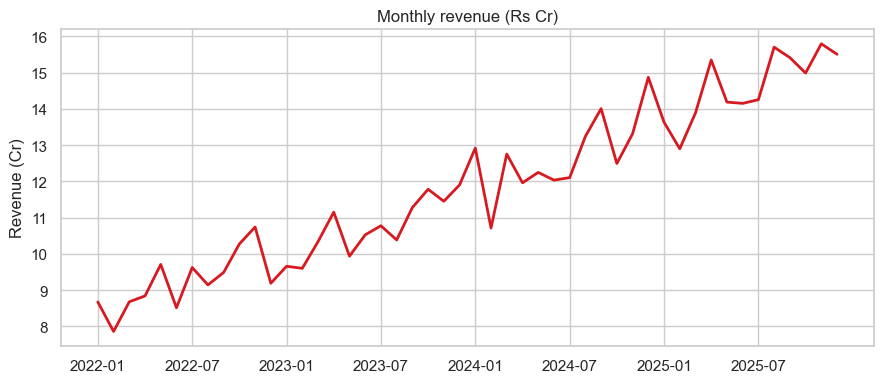

In [22]:
monthly = df.groupby("YearMonth")["Revenue"].sum().div(1e7)
plt.plot(monthly.index, monthly.values, color="#D71920", linewidth=2)
plt.xticks(range(0, len(monthly), 6), monthly.index[::6])
plt.title("Monthly revenue (Rs Cr)"); plt.ylabel("Revenue (Cr)")
plt.tight_layout(); plt.savefig("images/01_monthly_revenue.png"); plt.show()

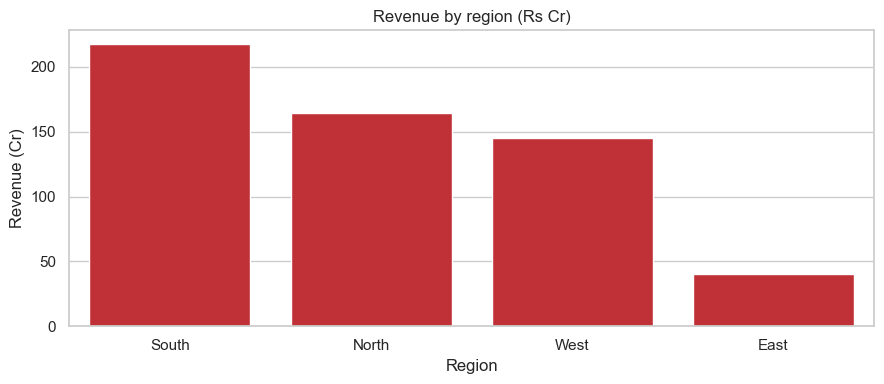

In [23]:
sns.barplot(x=by_region.index, y=by_region.values, color="#D71920")
plt.title("Revenue by region (Rs Cr)"); plt.ylabel("Revenue (Cr)")
plt.tight_layout(); plt.savefig("images/02_region.png"); plt.show()

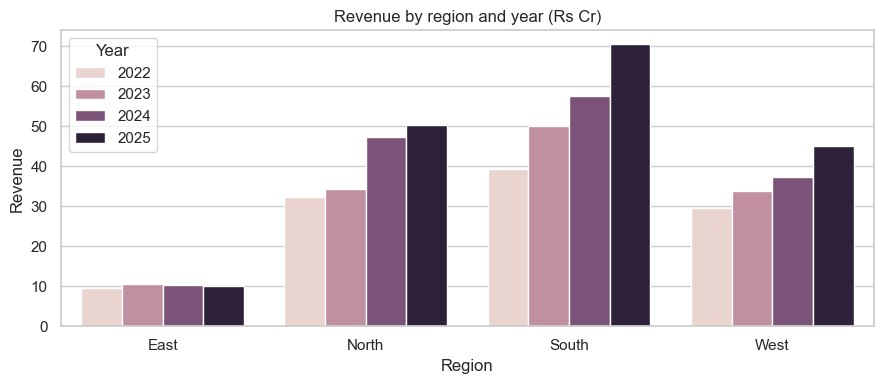

In [24]:
reg_year = df.groupby(["Year", "Region"])["Revenue"].sum().div(1e7).reset_index()
sns.barplot(data=reg_year, x="Region", y="Revenue", hue="Year")
plt.title("Revenue by region and year (Rs Cr)")
plt.tight_layout(); plt.savefig("images/03_region_year.png"); plt.show()

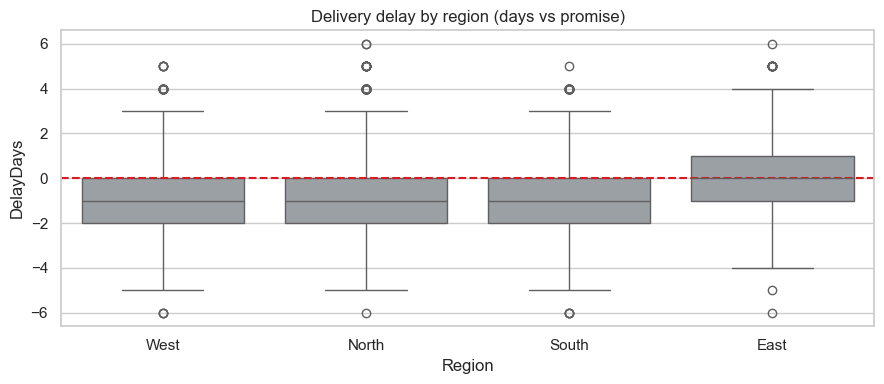

In [25]:
df["DelayDays"] = df["DeliveryDays"] - df["PromisedDays"]
sns.boxplot(data=df, x="Region", y="DelayDays", color="#9AA0A6")
plt.axhline(0, color="#D71920", linestyle="--")      # 0 = barobar promise kelelya vaelela
plt.title("Delivery delay by region (days vs promise)")
plt.tight_layout(); plt.savefig("images/04_delivery_box.png"); plt.show()

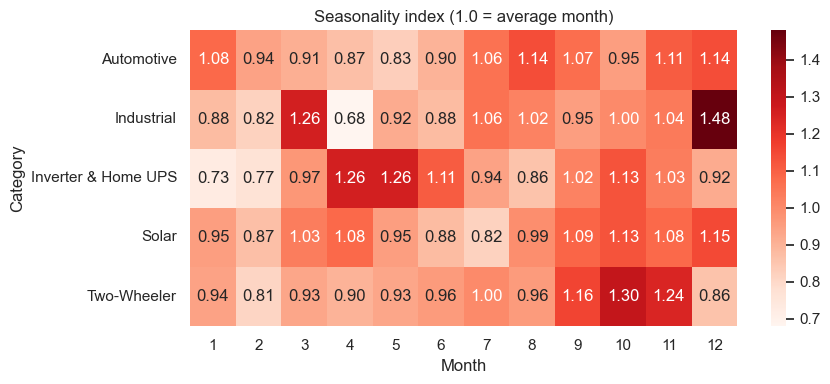

In [26]:
heat = df.pivot_table(index="Category", columns="Month", values="Revenue", aggfunc="sum")
heat = heat.div(heat.mean(axis=1), axis=0).round(2)
sns.heatmap(heat, annot=True, cmap="Reds", fmt=".2f")
plt.title("Seasonality index (1.0 = average month)")
plt.tight_layout(); plt.savefig("images/05_seasonality.png"); plt.show()

## Step A: Warranty claim rate by category
**Operation:** claims table la product table shi jodto (merge), mag pratyek category sathi claimed units / sold units kadhto.
**Why:** konta product category jast fail hoto, ani warranty cost kuthun yetoy.
**Output:** claim rate table + bar chart (06_claim_rate.png)

Category
Inverter & Home UPS    2.07
Two-Wheeler            1.71
Automotive             1.35
Solar                  0.83
Industrial             0.70
dtype: float64


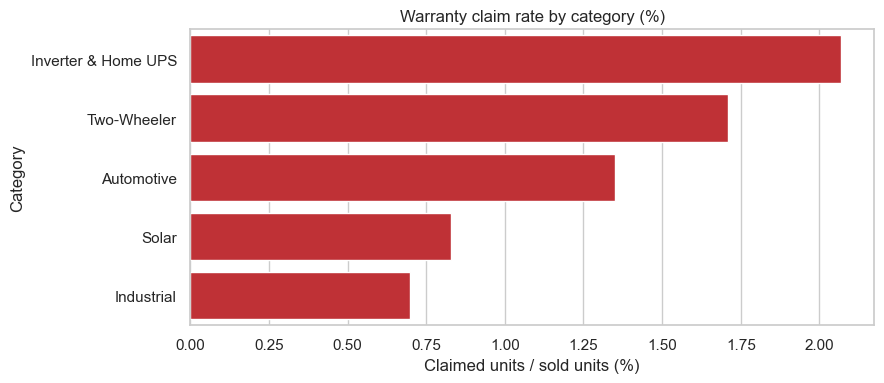

In [27]:
w = war.merge(prod[["ProductID", "Category"]], on="ProductID", how="left")

claimed = w.groupby("Category")["QtyClaimed"].sum()
sold    = df.groupby("Category")["Quantity"].sum()
rate = (claimed / sold * 100).round(2).sort_values(ascending=False)
print(rate)

sns.barplot(x=rate.values, y=rate.index, color="#D71920")
plt.title("Warranty claim rate by category (%)")
plt.xlabel("Claimed units / sold units (%)")
plt.tight_layout(); plt.savefig("images/06_claim_rate.png"); plt.show()

## Step B: Claim reasons and status
**Operation:** Reason ani ClaimStatus count karto, approval rate kadhto (Pending vagal).
**Why:** claims ka yetat, ani kiti approve hotat (kharee defect vs chukiche claims).
**Output:** top 5 reasons, status counts, approval rate.

In [28]:
print(w["Reason"].value_counts().head(5))
print()
print(w["ClaimStatus"].value_counts())

decided = w[w["ClaimStatus"] != "Pending"]
print("Approval rate %:", round((decided["ClaimStatus"] == "Approved").mean() * 100, 1))

Reason
Low Capacity / Poor Backup    1760
Sulphation                    1103
Terminal Corrosion            1088
Cell Short Circuit            1037
Manufacturing Defect           963
Name: count, dtype: int64

ClaimStatus
Approved    5659
Rejected    2733
Pending      138
Name: count, dtype: int64
Approval rate %: 67.4


## Step C: Find the bad batch (one product)
**Operation:** Inva Master 150Ah (P013) cha pratyek Taloja batch sathi claim rate kadhto, mag bar chart.
**Why:** ek batch normal peksha jast fail zala ka te shodhto. Batch = plant code + production month (TLJ-2405 = Taloja plant, 2024 May).
**Output:** 4 batches cha 13-15% claim rate vs normal 1.7%, chart 07_bad_batch.png.

          sold  claimed  rate
BatchID                      
TLJ-2405   764    115.0  15.1
TLJ-2403   956    135.0  14.1
TLJ-2404   864    119.0  13.8
TLJ-2402   735     96.0  13.1
TLJ-2110    27      1.0   3.7
normal TLJ median rate: 1.7


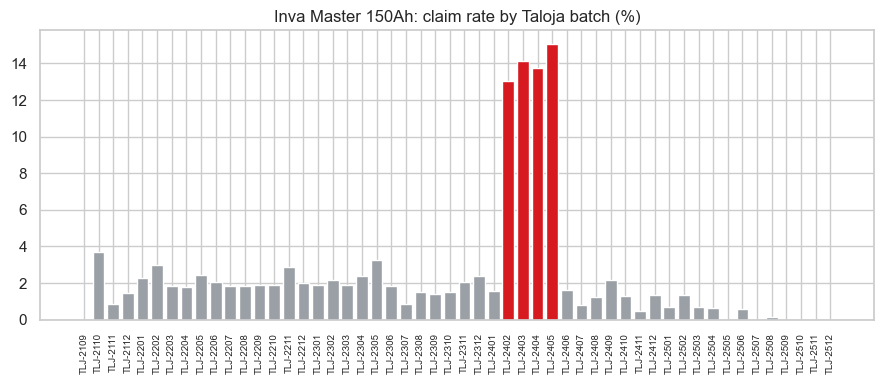

In [29]:
b = sales[sales["ProductID"] == "P013"].groupby("BatchID")["Quantity"].sum().rename("sold")
c = war[war["ProductID"] == "P013"].groupby("BatchID")["QtyClaimed"].sum().rename("claimed")

batch = pd.concat([b, c], axis=1).fillna(0)
batch["rate"] = batch["claimed"] / batch["sold"] * 100

tlj = batch[batch.index.str.startswith("TLJ")]        # Taloja plant cha batches
print(tlj.sort_values("rate", ascending=False).head(5).round(1))
print("normal TLJ median rate:", round(tlj["rate"].median(), 1))

colors = ["#D71920" if r > 8 else "#9AA0A6" for r in tlj["rate"]]
plt.bar(tlj.index, tlj["rate"], color=colors)
plt.xticks(rotation=90, fontsize=7)
plt.title("Inva Master 150Ah: claim rate by Taloja batch (%)")
plt.tight_layout(); plt.savefig("images/07_bad_batch.png"); plt.show()

## Step D: Scan all batches for abnormal claim rate
**Operation:** pratyek product-batch cha claim rate kadhto, product cha normal rate shi tulna, 2.5 pat peksha jast asel tar flag. 300 units peksha kami batches vagal.
**Why:** konta product kharab ahe te aadhi mahit nasto, mhanun sagle batches scan karto.
**Output:** 890 combos checked, 14 flagged (11 Taloja).

In [30]:
sold = sales.groupby(["BatchID", "ProductID"])["Quantity"].sum().rename("sold")
clm  = war.groupby(["BatchID", "ProductID"])["QtyClaimed"].sum().rename("claimed")
bp = pd.concat([sold, clm], axis=1).fillna(0).reset_index()
bp = bp[bp["sold"] >= 300].copy()
bp["rate"] = bp["claimed"] / bp["sold"] * 100

normal = bp.groupby("ProductID").apply(lambda g: g["claimed"].sum() / g["sold"].sum() * 100, include_groups=False).rename("normal")
bp = bp.merge(normal, on="ProductID")
bp["x_normal"] = bp["rate"] / bp["normal"]

bad = bp[bp["x_normal"] > 2.5].sort_values("x_normal", ascending=False).merge(prod[["ProductID", "ProductName"]], on="ProductID")
print(len(bp), "combos checked |", len(bad), "flagged")
print(bad[["BatchID", "ProductName", "sold", "claimed", "rate", "normal", "x_normal"]].round(1).head(8).to_string(index=False))
print(bad["BatchID"].str[:3].value_counts())

890 combos checked | 14 flagged
 BatchID             ProductName  sold  claimed  rate  normal  x_normal
TLJ-2405 Exide Inva Master 150Ah   764    115.0  15.1     2.7       5.6
TLJ-2403 Exide Inva Master 150Ah   956    135.0  14.1     2.7       5.3
TLJ-2402 Exide Inva Master 200Ah   535     77.0  14.4     2.8       5.2
TLJ-2404 Exide Inva Master 150Ah   864    119.0  13.8     2.7       5.1
TLJ-2404 Exide Inva Master 200Ah   473     67.0  14.2     2.8       5.1
TLJ-2403 Exide Inva Master 200Ah   390     53.0  13.6     2.8       4.9
TLJ-2402 Exide Inva Master 150Ah   735     96.0  13.1     2.7       4.9
TLJ-2405 Exide Inva Master 200Ah   622     79.0  12.7     2.8       4.6
BatchID
TLJ    11
HSR     2
SHM     1
Name: count, dtype: int64
